In [1]:
!pip install ucimlrepo

In [2]:
# IMPORTS COMPLETOS
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn import tree

In [3]:
# 1. ACESSO E CARREGAMENTO DOS DADOS VIA API DA UCI
# Dataset: Energy Efficiency - UCI Machine Learning Repository (ID: 242)
# Link: https://archive.ics.uci.edu/dataset/242/energy+efficiency

energy_efficiency = fetch_ucirepo(id=242)

X_original = energy_efficiency.data.features
y_original = energy_efficiency.data.targets

print("--- ALVOS ORIGINAIS (PRIMEIRAS LINHAS) ---")
print(y_original.head())

print("\n--- DIMENSÕES DO DATASET ---")
print(f"Quantidade de Instâncias: {X_original.shape[0]}")
print(f"Quantidade de Atributos Preditores: {X_original.shape[1]}")
print(f"Valores ausentes (missing values): {X_original.isnull().sum().sum()}")

--- ALVOS ORIGINAIS (PRIMEIRAS LINHAS) ---
      Y1     Y2
0  15.55  21.33
1  15.55  21.33
2  15.55  21.33
3  15.55  21.33
4  20.84  28.28

--- DIMENSÕES DO DATASET ---
Quantidade de Instâncias: 768
Quantidade de Atributos Preditores: 8
Valores ausentes (missing values): 0


--- ESTATÍSTICAS DESCRITIVAS ---
               X1          X2          X3          X4         X5          X6  \
count  768.000000  768.000000  768.000000  768.000000  768.00000  768.000000   
mean     0.764167  671.708333  318.500000  176.604167    5.25000    3.500000   
std      0.105777   88.086116   43.626481   45.165950    1.75114    1.118763   
min      0.620000  514.500000  245.000000  110.250000    3.50000    2.000000   
25%      0.682500  606.375000  294.000000  140.875000    3.50000    2.750000   
50%      0.750000  673.750000  318.500000  183.750000    5.25000    3.500000   
75%      0.830000  741.125000  343.000000  220.500000    7.00000    4.250000   
max      0.980000  808.500000  416.500000  220.500000    7.00000    5.000000   

               X7         X8  
count  768.000000  768.00000  
mean     0.234375    2.81250  
std      0.133221    1.55096  
min      0.000000    0.00000  
25%      0.100000    1.75000  
50%      0.250000    3.00000  
75%      0.400000    4.00000 

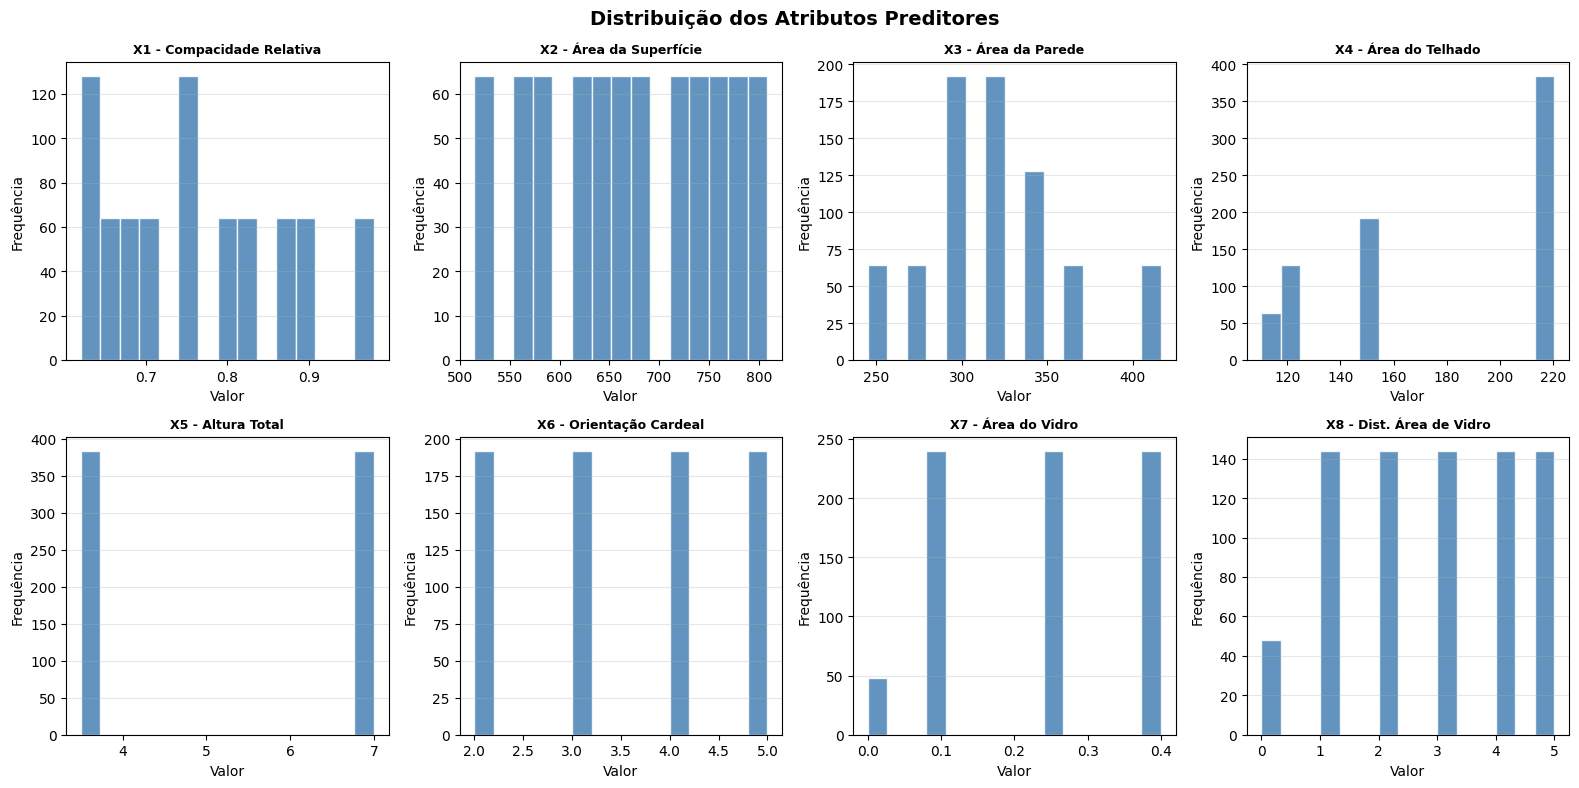

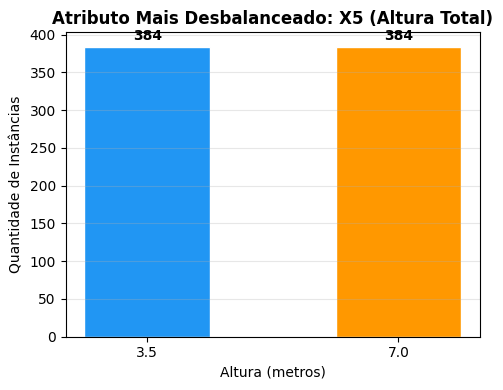

In [4]:
# 2. EXPLORAÇÃO E VISUALIZAÇÃO DOS DADOS

print("--- ESTATÍSTICAS DESCRITIVAS ---")
print(X_original.describe())

# Gráfico 1: Distribuição de cada atributo (histogramas)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Distribuição dos Atributos Preditores", fontsize=14, fontweight='bold')
atributos = ['X1 - Compacidade Relativa', 'X2 - Área da Superfície', 'X3 - Área da Parede',
             'X4 - Área do Telhado', 'X5 - Altura Total', 'X6 - Orientação Cardeal',
             'X7 - Área do Vidro', 'X8 - Dist. Área de Vidro']
for i, (ax, col, label) in enumerate(zip(axes.flat, X_original.columns, atributos)):
    ax.hist(X_original[col], bins=15, color='steelblue', edgecolor='white', alpha=0.85)
    ax.set_title(label, fontsize=9, fontweight='bold')
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frequência")
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('histogramas_atributos.png', dpi=150, bbox_inches='tight')
plt.show()

# Gráfico 2: Atributo mais desbalanceado - X5 (Altura Total)
fig, ax = plt.subplots(figsize=(5, 4))
contagem_x5 = X_original['X5'].value_counts().sort_index()
bars = ax.bar(contagem_x5.index.astype(str), contagem_x5.values, color=['#2196F3', '#FF9800'], edgecolor='white', width=0.5)
ax.set_title("Atributo Mais Desbalanceado: X5 (Altura Total)", fontweight='bold')
ax.set_xlabel("Altura (metros)")
ax.set_ylabel("Quantidade de Instâncias")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5,
            f'{bar.get_height()}', ha='center', va='bottom', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('atributo_desbalanceado_x5.png', dpi=150, bbox_inches='tight')
plt.show()

Mediana de Y1 (Carga de Aquecimento): 18.95

--- DISTRIBUIÇÃO DAS CLASSES APÓS BINARIZAÇÃO ---
  Classe 0 (Alta Eficiência): 384 instâncias (50.0%)
  Classe 1 (Baixa Eficiência): 384 instâncias (50.0%)


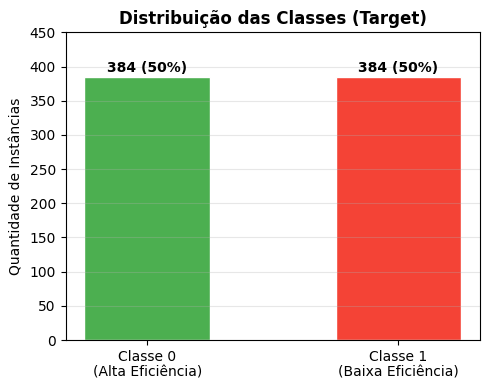


Conjunto de treino: 537 instâncias
Conjunto de teste:  231 instâncias

Normalização aplicada (StandardScaler) para KNN e Regressão Logística.
Média aproximada dos atributos após normalização: [ 0.  0. -0. -0. -0.  0.  0. -0.]


In [5]:
# 3. PRÉ-PROCESSAMENTO: DISCRETIZAÇÃO E NORMALIZAÇÃO

# 3.1 Binarização por mediana (Y1 - Heating Load)
mediana_y1 = y_original['Y1'].median()
print(f"Mediana de Y1 (Carga de Aquecimento): {mediana_y1}")

y_discreto = (y_original['Y1'] > mediana_y1).astype(int)

print("\n--- DISTRIBUIÇÃO DAS CLASSES APÓS BINARIZAÇÃO ---")
contagem = y_discreto.value_counts().sort_index()
for cls, qtd in contagem.items():
    nome = "Alta Eficiência" if cls == 0 else "Baixa Eficiência"
    print(f"  Classe {cls} ({nome}): {qtd} instâncias ({qtd/len(y_discreto)*100:.1f}%)")

# Gráfico da distribuição de classes
fig, ax = plt.subplots(figsize=(5, 4))
labels = ['Classe 0\n(Alta Eficiência)', 'Classe 1\n(Baixa Eficiência)']
cores = ['#4CAF50', '#F44336']
bars = ax.bar(labels, contagem.values, color=cores, edgecolor='white', width=0.5)
ax.set_title("Distribuição das Classes (Target)", fontweight='bold')
ax.set_ylabel("Quantidade de Instâncias")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 3,
            f'{bar.get_height()} (50%)', ha='center', va='bottom', fontweight='bold')
ax.set_ylim(0, 450)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('distribuicao_classes.png', dpi=150, bbox_inches='tight')
plt.show()

X = X_original
y = y_discreto

# 3.2 Divisão Holdout 70/30
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, shuffle=True, random_state=42
)
print(f"\nConjunto de treino: {X_train.shape[0]} instâncias")
print(f"Conjunto de teste:  {X_test.shape[0]} instâncias")

# 3.3 Normalização (StandardScaler) - aplicada ao KNN e Regressão Logística
# A Árvore de Decisão não depende de escala, portanto não necessita normalização.
# KNN usa distância euclidiana e Regressão Logística converge melhor com dados padronizados.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit apenas no treino para evitar data leakage
X_test_scaled = scaler.transform(X_test)

print("\nNormalização aplicada (StandardScaler) para KNN e Regressão Logística.")
print("Média aproximada dos atributos após normalização:", X_train_scaled.mean(axis=0).round(4))


 RESULTADOS DO ALGORITMO: Árvore de Decisão
  [sem normalização]
Tempo de treinamento: 0.008994 segundos

Relatório de Classificação:
                      precision    recall  f1-score   support

 Alta Eficiência (0)       0.97      0.94      0.96       106
Baixa Eficiência (1)       0.95      0.98      0.96       125

            accuracy                           0.96       231
           macro avg       0.96      0.96      0.96       231
        weighted avg       0.96      0.96      0.96       231



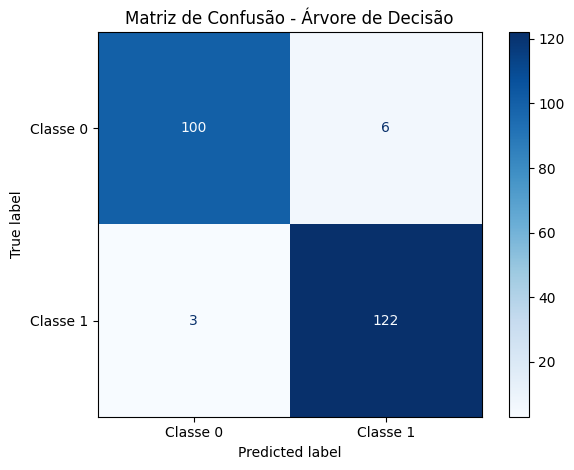


 RESULTADOS DO ALGORITMO: KNN (K=5)
  [com normalização]
Tempo de treinamento: 0.011911 segundos

Relatório de Classificação:
                      precision    recall  f1-score   support

 Alta Eficiência (0)       0.95      0.99      0.97       106
Baixa Eficiência (1)       0.99      0.96      0.98       125

            accuracy                           0.97       231
           macro avg       0.97      0.98      0.97       231
        weighted avg       0.97      0.97      0.97       231



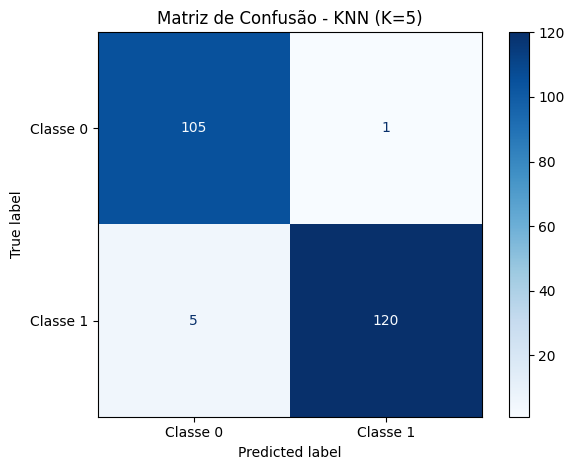


 RESULTADOS DO ALGORITMO: Regressão Logística
  [com normalização]
Tempo de treinamento: 0.098024 segundos

Relatório de Classificação:
                      precision    recall  f1-score   support

 Alta Eficiência (0)       0.96      0.99      0.98       106
Baixa Eficiência (1)       0.99      0.97      0.98       125

            accuracy                           0.98       231
           macro avg       0.98      0.98      0.98       231
        weighted avg       0.98      0.98      0.98       231



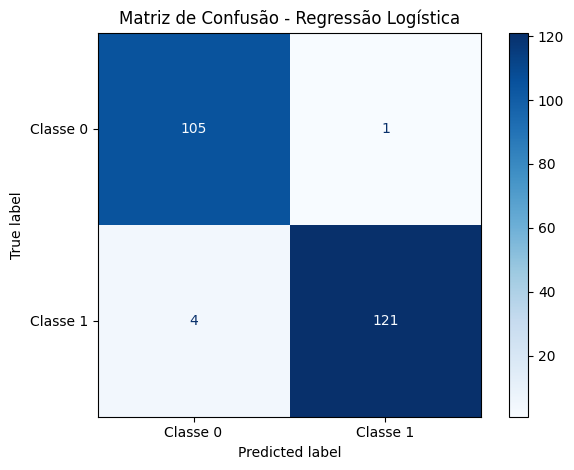

In [6]:
# 4. TREINAMENTO E AVALIAÇÃO DOS 3 ALGORITMOS

modelos = {
    "Árvore de Decisão": {
        "modelo": DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42),
        "normalizado": False  # Árvore não precisa de normalização
    },
    "KNN (K=5)": {
        "modelo": KNeighborsClassifier(n_neighbors=5),
        "normalizado": True   # KNN requer normalização (distância euclidiana)
    },
    "Regressão Logística": {
        "modelo": LogisticRegression(max_iter=1000, random_state=42),
        "normalizado": True   # LR converge melhor com dados padronizados
    }
}

resultados = {}

for nome, config in modelos.items():
    modelo = config["modelo"]
    usar_normalizado = config["normalizado"]

    X_tr = X_train_scaled if usar_normalizado else X_train
    X_te = X_test_scaled if usar_normalizado else X_test

    # Medição do tempo de treino
    tempo_inicial = time.time()
    modelo.fit(X_tr, y_train)
    tempo_final = time.time()
    tempo_execucao = tempo_final - tempo_inicial

    y_pred = modelo.predict(X_te)

    report_dict = classification_report(
        y_test, y_pred,
        target_names=["Alta Eficiência (0)", "Baixa Eficiência (1)"],
        output_dict=True
    )
    resultados[nome] = {
        "tempo": tempo_execucao,
        "y_pred": y_pred,
        "report": report_dict
    }

    print(f"\n=======================================================")
    print(f" RESULTADOS DO ALGORITMO: {nome}")
    norm_str = " [com normalização]" if usar_normalizado else " [sem normalização]"
    print(f" {norm_str}")
    print(f"=======================================================")
    print(f"Tempo de treinamento: {tempo_execucao:.6f} segundos")
    print("\nRelatório de Classificação:")
    print(classification_report(y_test, y_pred, target_names=["Alta Eficiência (0)", "Baixa Eficiência (1)"]))

    # Matriz de confusão
    disp = ConfusionMatrixDisplay.from_estimator(
        modelo, X_te, y_test, display_labels=["Classe 0", "Classe 1"], cmap="Blues"
    )
    plt.title(f"Matriz de Confusão - {nome}")
    plt.grid(False)
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{nome.replace(" ","_").replace("(","").replace(")","")}.png', dpi=150)
    plt.show()

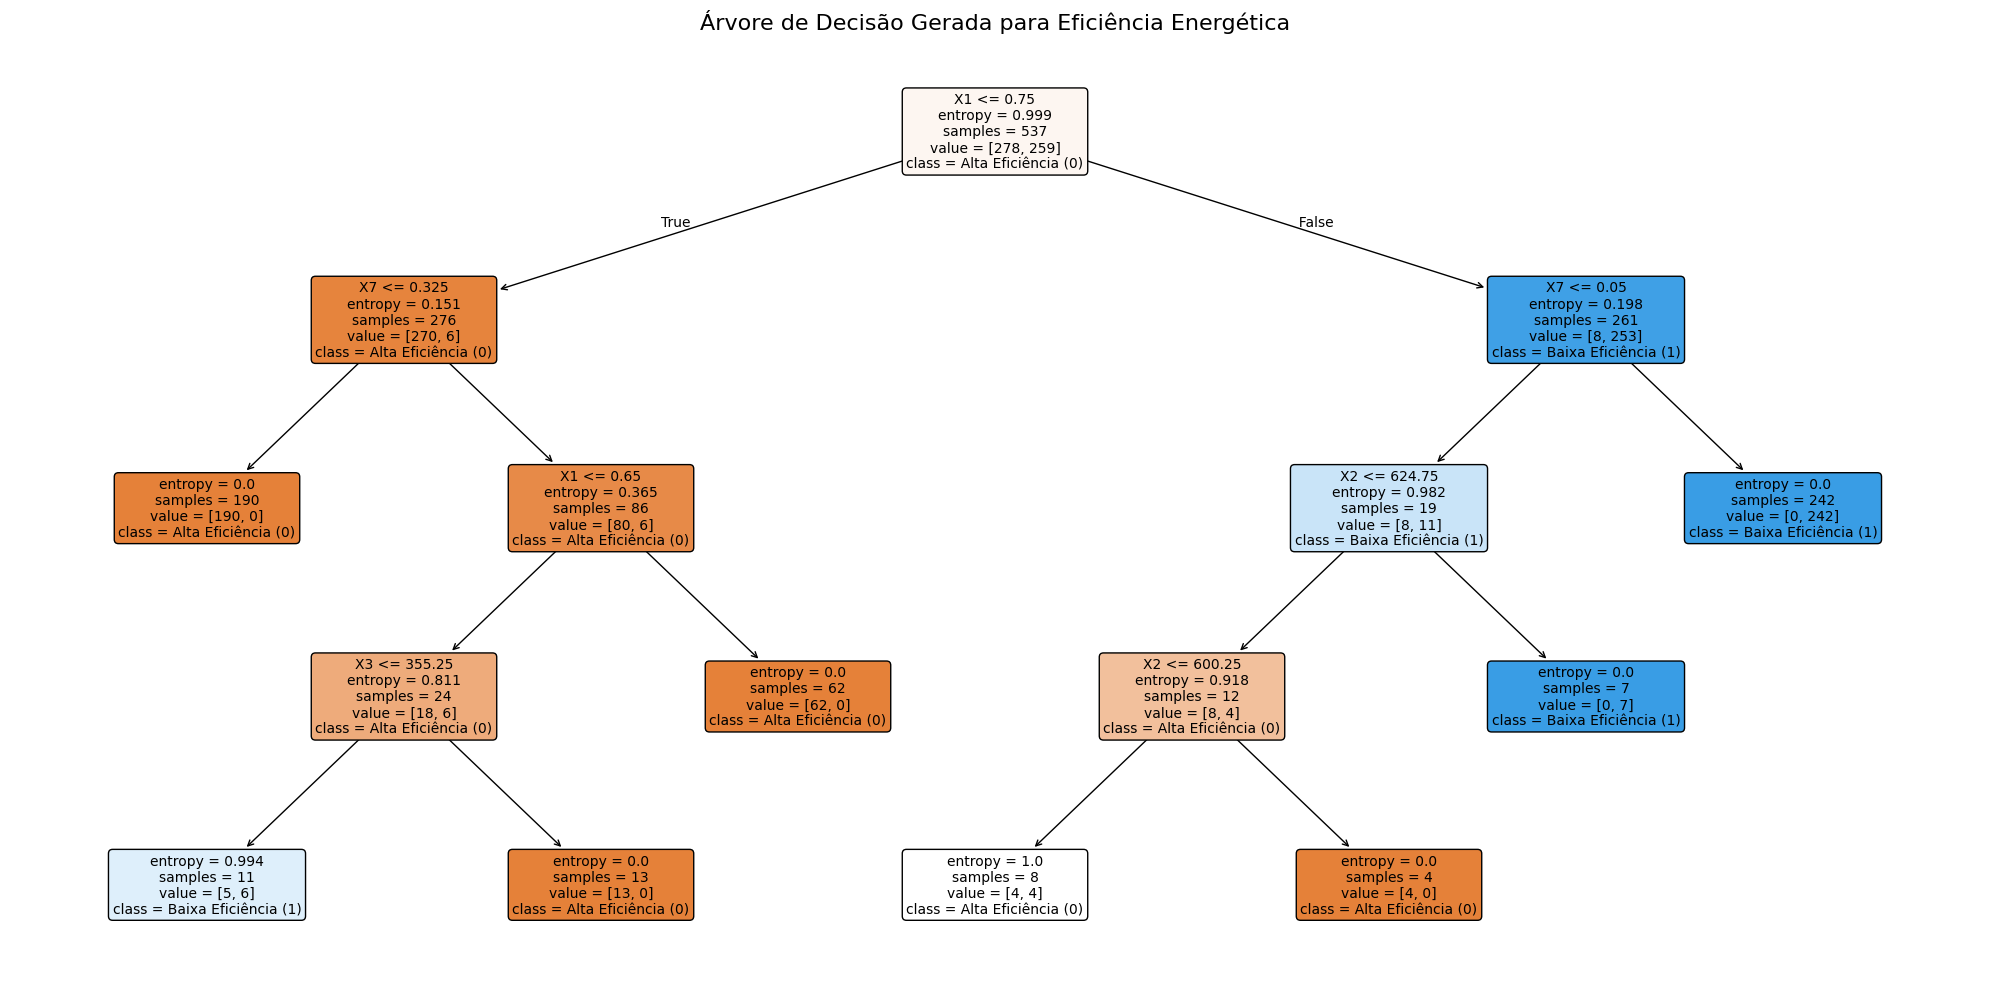

In [7]:
# 5. VISUALIZAÇÃO DA ÁRVORE DE DECISÃO

plt.figure(figsize=(20, 10))
tree.plot_tree(
    modelos["Árvore de Decisão"]["modelo"],
    rounded=True,
    feature_names=X.columns,
    fontsize=10,
    class_names=["Alta Eficiência (0)", "Baixa Eficiência (1)"],
    filled=True
)
plt.title("Árvore de Decisão Gerada para Eficiência Energética", fontsize=16)
plt.tight_layout()
plt.savefig('arvore_decisao.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# 6. TABELA COMPARATIVA FINAL DE RESULTADOS

print("\n" + "="*85)
print(f"{'ALGORITMO':<22} {'ACURÁCIA':>10} {'PRECISÃO':>10} {'RECALL':>10} {'F1-SCORE':>10} {'TEMPO (s)':>12}")
print("="*85)
for nome, res in resultados.items():
    r = res["report"]
    acc = r["accuracy"]
    prec = r["macro avg"]["precision"]
    recall = r["macro avg"]["recall"]
    f1 = r["macro avg"]["f1-score"]
    tempo = res["tempo"]
    norm = " *" if modelos[nome]["normalizado"] else "  "
    print(f"{nome+norm:<22} {acc*100:>9.2f}% {prec:>10.3f} {recall:>10.3f} {f1:>10.3f} {tempo:>12.6f}")
print("="*85)
print("* Algoritmos marcados com (*) utilizaram normalização via StandardScaler")

print("\n--- ANÁLISE POR CLASSE - ÁRVORE DE DECISÃO (pior resultado) ---")
r_dt = resultados["Árvore de Decisão"]["report"]
print(f"  Classe 0 (Alta Eficiência): Precisão={r_dt['Alta Eficiência (0)']['precision']:.2f}, Recall={r_dt['Alta Eficiência (0)']['recall']:.2f}, F1={r_dt['Alta Eficiência (0)']['f1-score']:.2f}")
print(f"  Classe 1 (Baixa Eficiência): Precisão={r_dt['Baixa Eficiência (1)']['precision']:.2f}, Recall={r_dt['Baixa Eficiência (1)']['recall']:.2f}, F1={r_dt['Baixa Eficiência (1)']['f1-score']:.2f}")

print("\n--- ANÁLISE POR CLASSE - KNN K=5 (melhor resultado) ---")
r_knn = resultados["KNN (K=5)"]["report"]
print(f"  Classe 0 (Alta Eficiência): Precisão={r_knn['Alta Eficiência (0)']['precision']:.2f}, Recall={r_knn['Alta Eficiência (0)']['recall']:.2f}, F1={r_knn['Alta Eficiência (0)']['f1-score']:.2f}")
print(f"  Classe 1 (Baixa Eficiência): Precisão={r_knn['Baixa Eficiência (1)']['precision']:.2f}, Recall={r_knn['Baixa Eficiência (1)']['recall']:.2f}, F1={r_knn['Baixa Eficiência (1)']['f1-score']:.2f}")


ALGORITMO                ACURÁCIA   PRECISÃO     RECALL   F1-SCORE    TEMPO (s)
Árvore de Decisão          96.10%      0.962      0.960      0.961     0.008994
KNN (K=5) *                97.40%      0.973      0.975      0.974     0.011911
Regressão Logística *      97.84%      0.978      0.979      0.978     0.098024
* Algoritmos marcados com (*) utilizaram normalização via StandardScaler

--- ANÁLISE POR CLASSE - ÁRVORE DE DECISÃO (pior resultado) ---
  Classe 0 (Alta Eficiência): Precisão=0.97, Recall=0.94, F1=0.96
  Classe 1 (Baixa Eficiência): Precisão=0.95, Recall=0.98, F1=0.96

--- ANÁLISE POR CLASSE - KNN K=5 (melhor resultado) ---
  Classe 0 (Alta Eficiência): Precisão=0.95, Recall=0.99, F1=0.97
  Classe 1 (Baixa Eficiência): Precisão=0.99, Recall=0.96, F1=0.98
